In [24]:
import pandas as pd

# 1. Read the datasets (skipping the first 8 rows of metadata)
# Note: Ensure these file names match the files in your local directory
file_recent = "../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21357526_spreadsheet.xlsx"
file_hist = "../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21357611_spreadsheet.xlsx"

df_recent = pd.read_excel(file_recent, sheet_name='employment', skiprows=8)
df_hist = pd.read_excel(file_hist, sheet_name='employment', skiprows=8)

# 2. Define a function to clean and format the data
def clean_eurostat_df(df, year_columns):
    df_clean = df.copy()
    
    # Rename standard geographic columns for easier merging
    df_clean = df_clean.rename(columns={'TIME': 'GEO_Code', 'TIME.1': 'GEO_Label'})
    
    # Drop the first row which usually contains "GEO (Codes)" text
    df_clean = df_clean.drop(0) 
    
    # Filter only the columns we need (Geography + Years)
    cols_to_keep = ['GEO_Code', 'GEO_Label'] + year_columns
    existing_cols = [c for c in cols_to_keep if c in df_clean.columns]
    df_clean = df_clean[existing_cols]
    
    # Convert year columns to numeric, handling Eurostat specific flags
    for col in year_columns:
        if col in df_clean.columns:
            # Remove ':' (not available) and strip whitespace, then coerce to numeric
            # This turns 'C' (confidential) and 'b' (break in series) into NaN (Not a Number)
            df_clean[col] = pd.to_numeric(
                df_clean[col].astype(str).str.replace(':', '', regex=False).str.strip(), 
                errors='coerce'
            )
            
    return df_clean

# Define the years present in each dataset
years_hist = [str(y) for y in range(2008, 2021)]
years_recent = [str(y) for y in range(2021, 2024)]

# Clean both datasets
df_hist_clean = clean_eurostat_df(df_hist, years_hist)
df_recent_clean = clean_eurostat_df(df_recent, years_recent)

# 3. Merge the datasets based on the Geographic Code and Label
df_merged = pd.merge(df_hist_clean, df_recent_clean, on=['GEO_Code', 'GEO_Label'], how='outer')

# 4. Filter for Country-level data only (NUTS 0)
# Country codes in Eurostat are generally 2 characters long (e.g., 'DE', 'FR')
df_countries = df_merged[df_merged['GEO_Code'].str.len() == 2].copy()

# Filter out generic Eurostat aggregates like 'EU' (European Union) or 'EA' (Euro Area)
not_countries = ['EU', 'EA', 'EU27_2020']
df_countries = df_countries[~df_countries['GEO_Code'].isin(not_countries)]

# 5. Calculate the average employment to find the top 5
all_years = [y for y in years_hist + years_recent if y in df_countries.columns]
df_countries['Mean_Emp'] = df_countries[all_years].mean(axis=1)

top_5_countries = df_countries.nlargest(5, 'Mean_Emp')

# Print the results
print("Top 5 Countries by average employment in Motor Vehicle Manufacturing:")
print(top_5_countries[['GEO_Code', 'GEO_Label', 'Mean_Emp']])

# Optional: Save the merged data to a new CSV file
df_countries.to_excel('../../03_data_raw/exploration_inputs/merged_country_employment.xlsx', index=False)

Top 5 Countries by average employment in Motor Vehicle Manufacturing:
    GEO_Code GEO_Label       Mean_Emp
59        DE   Germany  879765.625000
205       FR    France  218828.928571
410       PL    Poland  181492.562500
318       IT     Italy  163670.562500
46        CZ   Czechia  161309.750000


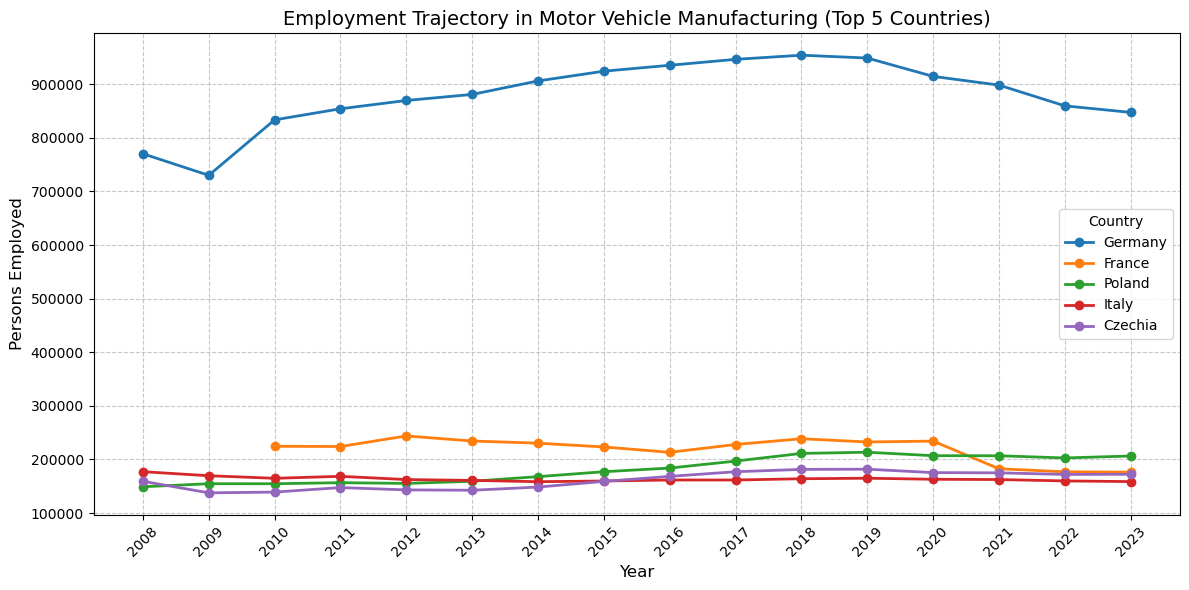

In [5]:
import matplotlib.pyplot as plt

# --- This assumes you have already run the previous code ---
# 'top_5_countries' and 'all_years' should already be defined.

# 1. Set up the size of the graph (width=12, height=6)
plt.figure(figsize=(12, 6))

# 2. Loop through each of the top 5 countries and plot their data
for index, row in top_5_countries.iterrows():
    # Plot the years on the X-axis and employment numbers on the Y-axis
    plt.plot(all_years, row[all_years], marker='o', linewidth=2, label=row['GEO_Label'])

# 3. Add title and axis labels
plt.title('Employment Trajectory in Motor Vehicle Manufacturing (Top 5 Countries)', fontsize=14)
plt.xlabel('Year', fontsize=12)
plt.ylabel('Persons Employed', fontsize=12)

# 4. Add a legend, a grid, and format the X-axis labels so they don't overlap
plt.legend(title='Country', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.7)
plt.xticks(rotation=45)

# Adjust layout to make sure everything fits nicely
plt.tight_layout()

# 5. Display the plot on your screen
plt.show()

# Optional: If you want to save it as an image file instead of displaying it, 
# comment out plt.show() and use the line below:
# plt.savefig('top5_employment_trajectory.png')

In [21]:
import pandas as pd

# 1. Read the Local Units datasets (skipping the 8 rows of metadata)
# Note: Ensure these file names match the files in your local directory
file_recent_units = "../../03_data_raw/exploration_inputs/sbs_r_nuts2021__custom_21357526_spreadsheet.xlsx"
file_hist_units = "../../03_data_raw/exploration_inputs/sbs_r_nuts06_r2__custom_21357611_spreadsheet.xlsx"

df_recent_units = pd.read_excel(file_recent, sheet_name='units', skiprows=8)
df_hist_units = pd.read_excel(file_hist, sheet_name='units', skiprows=8)

# 2. Define the cleaning function (same as before)
def clean_eurostat_df(df, year_columns):
    df_clean = df.copy()
    
    # Rename standard geographic columns
    df_clean = df_clean.rename(columns={'TIME': 'GEO_Code', 'TIME.1': 'GEO_Label'})
    df_clean = df_clean.drop(0) # Drop the "GEO (Codes)" row
    
    # Filter only the columns we need (Geography + Years)
    cols_to_keep = ['GEO_Code', 'GEO_Label'] + year_columns
    existing_cols = [c for c in cols_to_keep if c in df_clean.columns]
    df_clean = df_clean[existing_cols]
    
    # Convert year columns to numeric, handling Eurostat specific flags like 'C' or 'b'
    for col in year_columns:
        if col in df_clean.columns:
            df_clean[col] = pd.to_numeric(
                df_clean[col].astype(str).str.replace(':', '', regex=False).str.strip(), 
                errors='coerce'
            )
            
    return df_clean

# Define the years present in each dataset
years_hist = [str(y) for y in range(2008, 2021)]
years_recent = [str(y) for y in range(2021, 2024)]

# Clean both datasets
df_hist_units_clean = clean_eurostat_df(df_hist_units, years_hist)
df_recent_units_clean = clean_eurostat_df(df_recent_units, years_recent)

# 3. Merge the datasets based on Geographic Code and Label
units_merged = pd.merge(df_hist_units_clean, df_recent_units_clean, on=['GEO_Code', 'GEO_Label'], how='outer')

# 4. Filter for Country-level data only (NUTS 0)
units = units_merged[units_merged['GEO_Code'].str.len() == 2].copy()

# Filter out generic Eurostat aggregates
not_countries = ['EU', 'EA', 'EU27_2020']
units = units[~units['GEO_Code'].isin(not_countries)]

# Display the first few rows to verify the successful merge
print("Preview of the 'units' DataFrame:")
print(units.head())

# Optional: Save the units data to a CSV file
# units.to_csv('merged_country_units.csv', index=False)

Preview of the 'units' DataFrame:
   GEO_Code GEO_Label    2008    2009    2010    2011    2012    2013    2014  \
1        AT   Austria   353.0   339.0   357.0   371.0   353.0   362.0   373.0   
16       BE   Belgium   583.0   469.0   553.0   441.0   383.0   415.0   382.0   
33       BG  Bulgaria    99.0   104.0   110.0   113.0   113.0   114.0   117.0   
43       CY    Cyprus    92.0    92.0    84.0    82.0    78.0    74.0    72.0   
46       CZ   Czechia  1323.0  1366.0  1438.0  1393.0  1360.0  1286.0  1279.0   

      2015    2016    2017    2018    2019    2020    2021    2022    2023  
1    285.0   277.0   271.0   278.0   284.0   287.0   315.0   323.0   322.0  
16   369.0   350.0   393.0   425.0   461.0   510.0   336.0   543.0   487.0  
33   118.0   123.0   120.0   129.0   145.0   148.0   156.0   155.0   159.0  
43    71.0    70.0    66.0    69.0    65.0    65.0    63.0    61.0    61.0  
46  1273.0  1292.0  1281.0  1301.0  1359.0  1360.0  1384.0  1376.0  1360.0  


In [25]:
units_merged

,GEO_Code,GEO_Label,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
0,:,not available,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AT,Austria,353.0,339.0,357.0,371.0,353.0,362.0,373.0,285.0,277.0,271.0,278.0,284.0,287.0,315.0,323.0,322.0
2,AT1,Ostösterreich,95.0,91.0,97.0,101.0,97.0,98.0,103.0,74.0,66.0,72.0,75.0,85.0,86.0,88.0,86.0,84.0
3,AT11,Burgenland,8.0,9.0,9.0,9.0,6.0,6.0,8.0,8.0,8.0,9.0,9.0,11.0,9.0,12.0,8.0,8.0
4,AT12,Niederösterreich,54.0,52.0,55.0,58.0,57.0,58.0,62.0,48.0,42.0,48.0,49.0,56.0,56.0,56.0,59.0,59.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
571,UKN0,Northern Ireland (UK) (NUTS 2021),132.0,136.0,122.0,114.0,110.0,112.0,97.0,96.0,105.0,105.0,112.0,NaN,NaN,NaN,NaN,NaN
572,b,break in time series,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
573,d,definition differs (see metadata),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
574,p,provisional,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [26]:
units_merged.to_excel('../../03_data_raw/exploration_inputs/units_merged.xlsx', index=False)

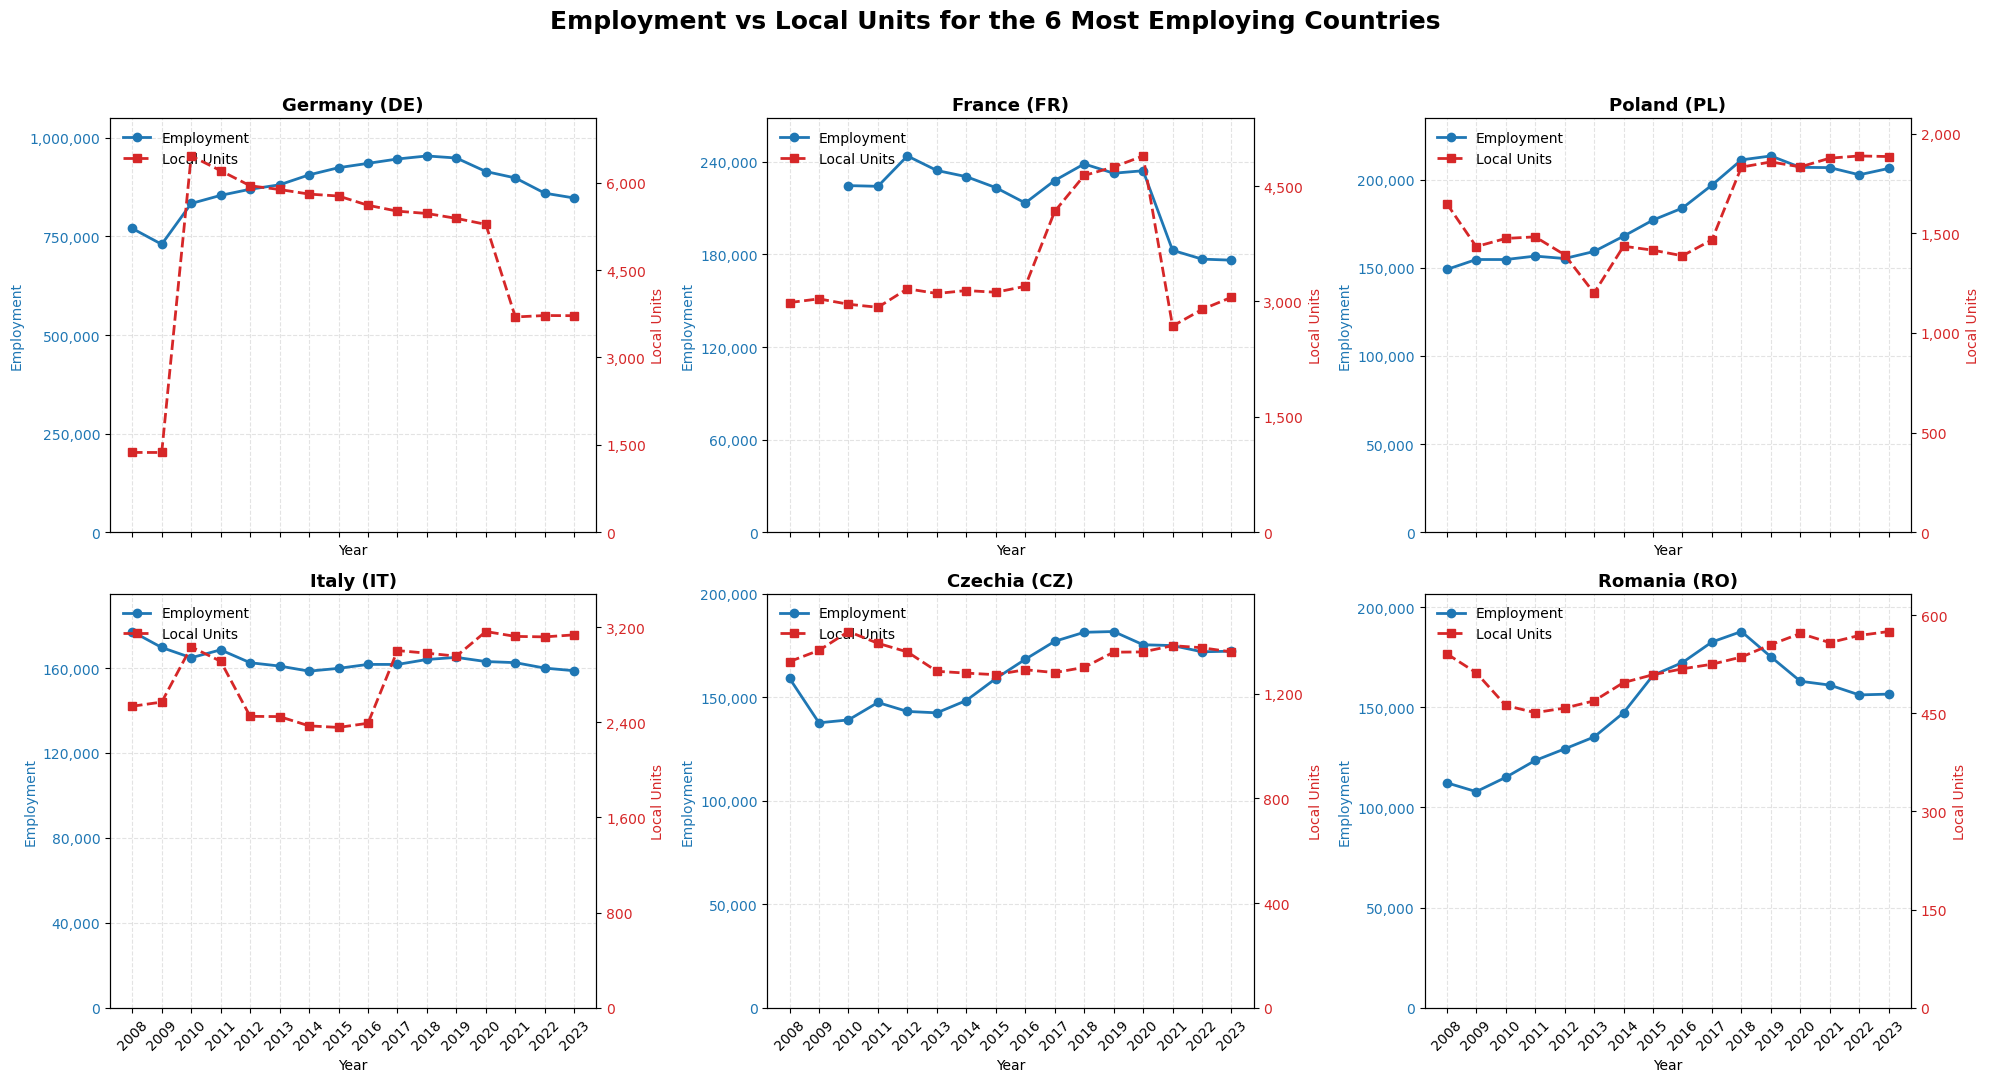

In [22]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import MaxNLocator, StrMethodFormatter

# Top 6 countries by average employment
top_6_countries = df_countries.nlargest(6, 'Mean_Emp').copy()
years = [str(y) for y in range(2008, 2024)]
valid_years = [y for y in years if y in df_countries.columns and y in units.columns]

fig, axes = plt.subplots(2, 3, figsize=(20, 11), sharex=True)
fig.suptitle('Employment vs Local Units for the 6 Most Employing Countries', fontsize=18, fontweight='bold')
axes = axes.flatten()

for ax, (_, row) in zip(axes, top_6_countries.iterrows()):
    code = row['GEO_Code']
    country_name = row['GEO_Label']

    emp_row = df_countries.loc[df_countries['GEO_Code'] == code, valid_years]
    emp_data = emp_row.iloc[0].to_numpy(dtype=float) if not emp_row.empty else np.full(len(valid_years), np.nan)

    unit_row = units.loc[units['GEO_Code'] == code, valid_years]
    unit_data = unit_row.iloc[0].to_numpy(dtype=float) if not unit_row.empty else np.full(len(valid_years), np.nan)

    ax2 = ax.twinx()
    line1, = ax.plot(valid_years, emp_data, color='tab:blue', marker='o', linewidth=2, label='Employment')
    line2, = ax2.plot(valid_years, unit_data, color='tab:red', marker='s', linestyle='--', linewidth=2, label='Local Units')

    ax.set_title(f'{country_name} ({code})', fontsize=13, fontweight='bold')
    ax.set_xlabel('Year')
    ax.set_ylabel('Employment', color='tab:blue')
    ax2.set_ylabel('Local Units', color='tab:red')

    ax.tick_params(axis='y', left=True, labelleft=True, right=False, labelright=False, labelcolor='tab:blue')
    ax2.tick_params(axis='y', right=True, labelright=True, left=False, labelleft=False, labelcolor='tab:red')
    ax.tick_params(axis='x', rotation=45)

    if not np.all(np.isnan(emp_data)):
        ax.set_ylim(0, np.nanmax(emp_data) * 1.1)
    if not np.all(np.isnan(unit_data)):
        ax2.set_ylim(0, np.nanmax(unit_data) * 1.1)

    ax.yaxis.set_major_locator(MaxNLocator(5))
    ax2.yaxis.set_major_locator(MaxNLocator(5))
    ax.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
    ax2.yaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))

    ax.grid(True, linestyle='--', alpha=0.35)
    ax.legend([line1, line2], ['Employment', 'Local Units'], loc='upper left', frameon=False)

for ax in axes[len(top_6_countries):]:
    fig.delaxes(ax)

fig.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

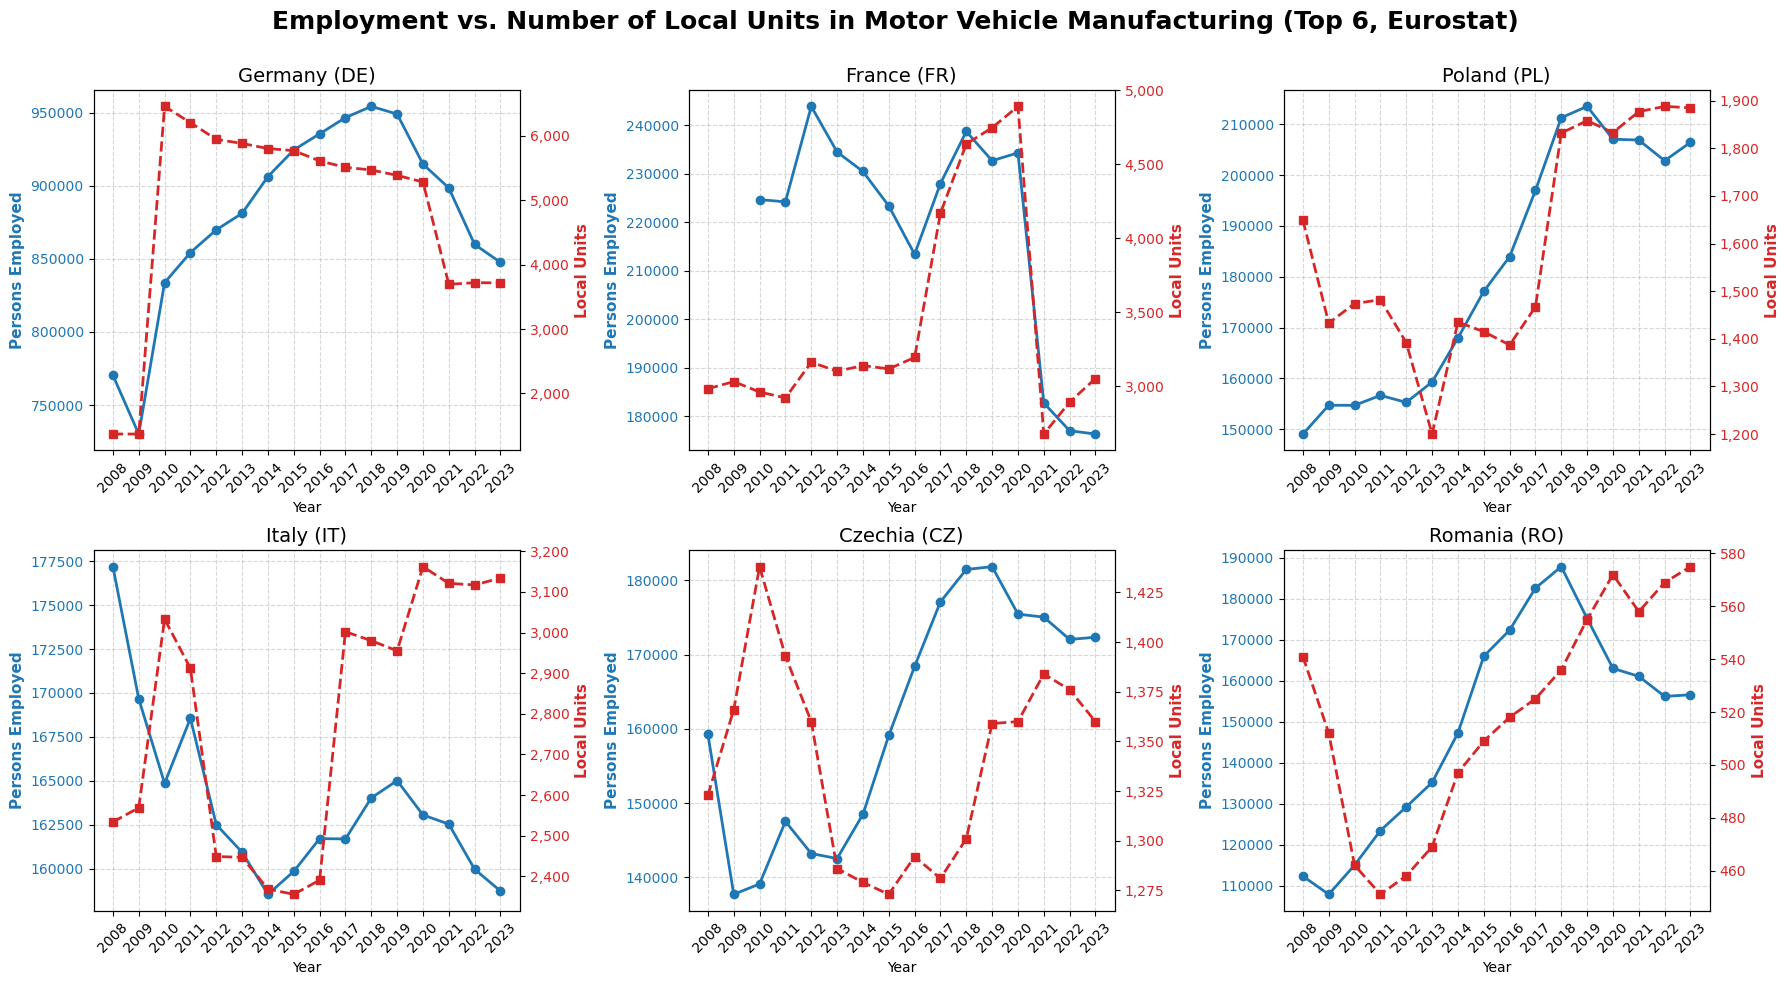

In [33]:
import matplotlib.pyplot as plt

# 1. Identify the top 6 employing countries
top_6_countries = df_countries.nlargest(6, 'Mean_Emp')
top_6_codes = top_6_countries['GEO_Code'].tolist()

# Define the years to plot (ensure they exist in both DataFrames)
all_years = [str(y) for y in range(2008, 2024)]
valid_years = [y for y in all_years if y in df_countries.columns and y in units.columns]

# 2. Set up the figure and a 2x3 grid of subplots
fig, axes = plt.subplots(nrows=2, ncols=3, figsize=(18, 10))
fig.suptitle('Employment vs. Number of Local Units in Motor Vehicle Manufacturing (Top 6, Eurostat)', fontsize=18, fontweight='bold')

# Flatten the 2x3 grid into a 1D array for easier looping
axes = axes.flatten()

# 3. Loop through the top 6 countries and create a dual-axis plot for each
for idx, code in enumerate(top_6_codes):
    ax1 = axes[idx]
    
    # Extract the data for the current country
    country_name = top_6_countries[top_6_countries['GEO_Code'] == code]['GEO_Label'].values[0]
    emp_data = df_countries[df_countries['GEO_Code'] == code][valid_years].values.flatten()
    
    # Handle cases where a country might be missing from the units dataset
    if code in units['GEO_Code'].values:
        units_data = units[units['GEO_Code'] == code][valid_years].values.flatten()
    else:
        units_data = [float('nan')] * len(valid_years)
    
    # --- Plot 1: Employment (Primary Y-Axis / Left side) ---
    color1 = 'tab:blue'
    ax1.set_xlabel('Year', fontsize=10)
    ax1.set_ylabel('Persons Employed', color=color1, fontsize=11, fontweight='bold')
    ax1.plot(valid_years, emp_data, color=color1, marker='o', linewidth=2, label='Employment')
    ax1.tick_params(axis='y', labelcolor=color1)
    ax1.tick_params(axis='x', rotation=45)
    ax1.set_title(f'{country_name} ({code})', fontsize=14)
    ax1.grid(True, linestyle='--', alpha=0.5)
    
    # --- Plot 2: Local Units (Secondary Y-Axis / Right side) ---
    ax2 = ax1.twinx()  # Create a second y-axis that shares the same x-axis
    color2 = 'tab:red'
    ax2.set_ylabel('Local Units', color=color2, fontsize=11, fontweight='bold')
    ax2.plot(valid_years, units_data, color=color2, marker='s', linestyle='--', linewidth=2, label='Local Units')
    ax2.tick_params(axis='y', labelcolor=color2)
    
    # To avoid the right y-axis numbers overlapping with the next plot, adjust formatting if needed
    ax2.yaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter('{x:,.0f}'))

# 4. Final layout adjustments
plt.tight_layout()
# Push the subplots slightly down to make room for the main super title
fig.subplots_adjust(top=0.90) 

# Display the plot
plt.show()

# Optional: Save the figure
# plt.savefig('top6_employment_vs_units.png', dpi=300, bbox_inches='tight')

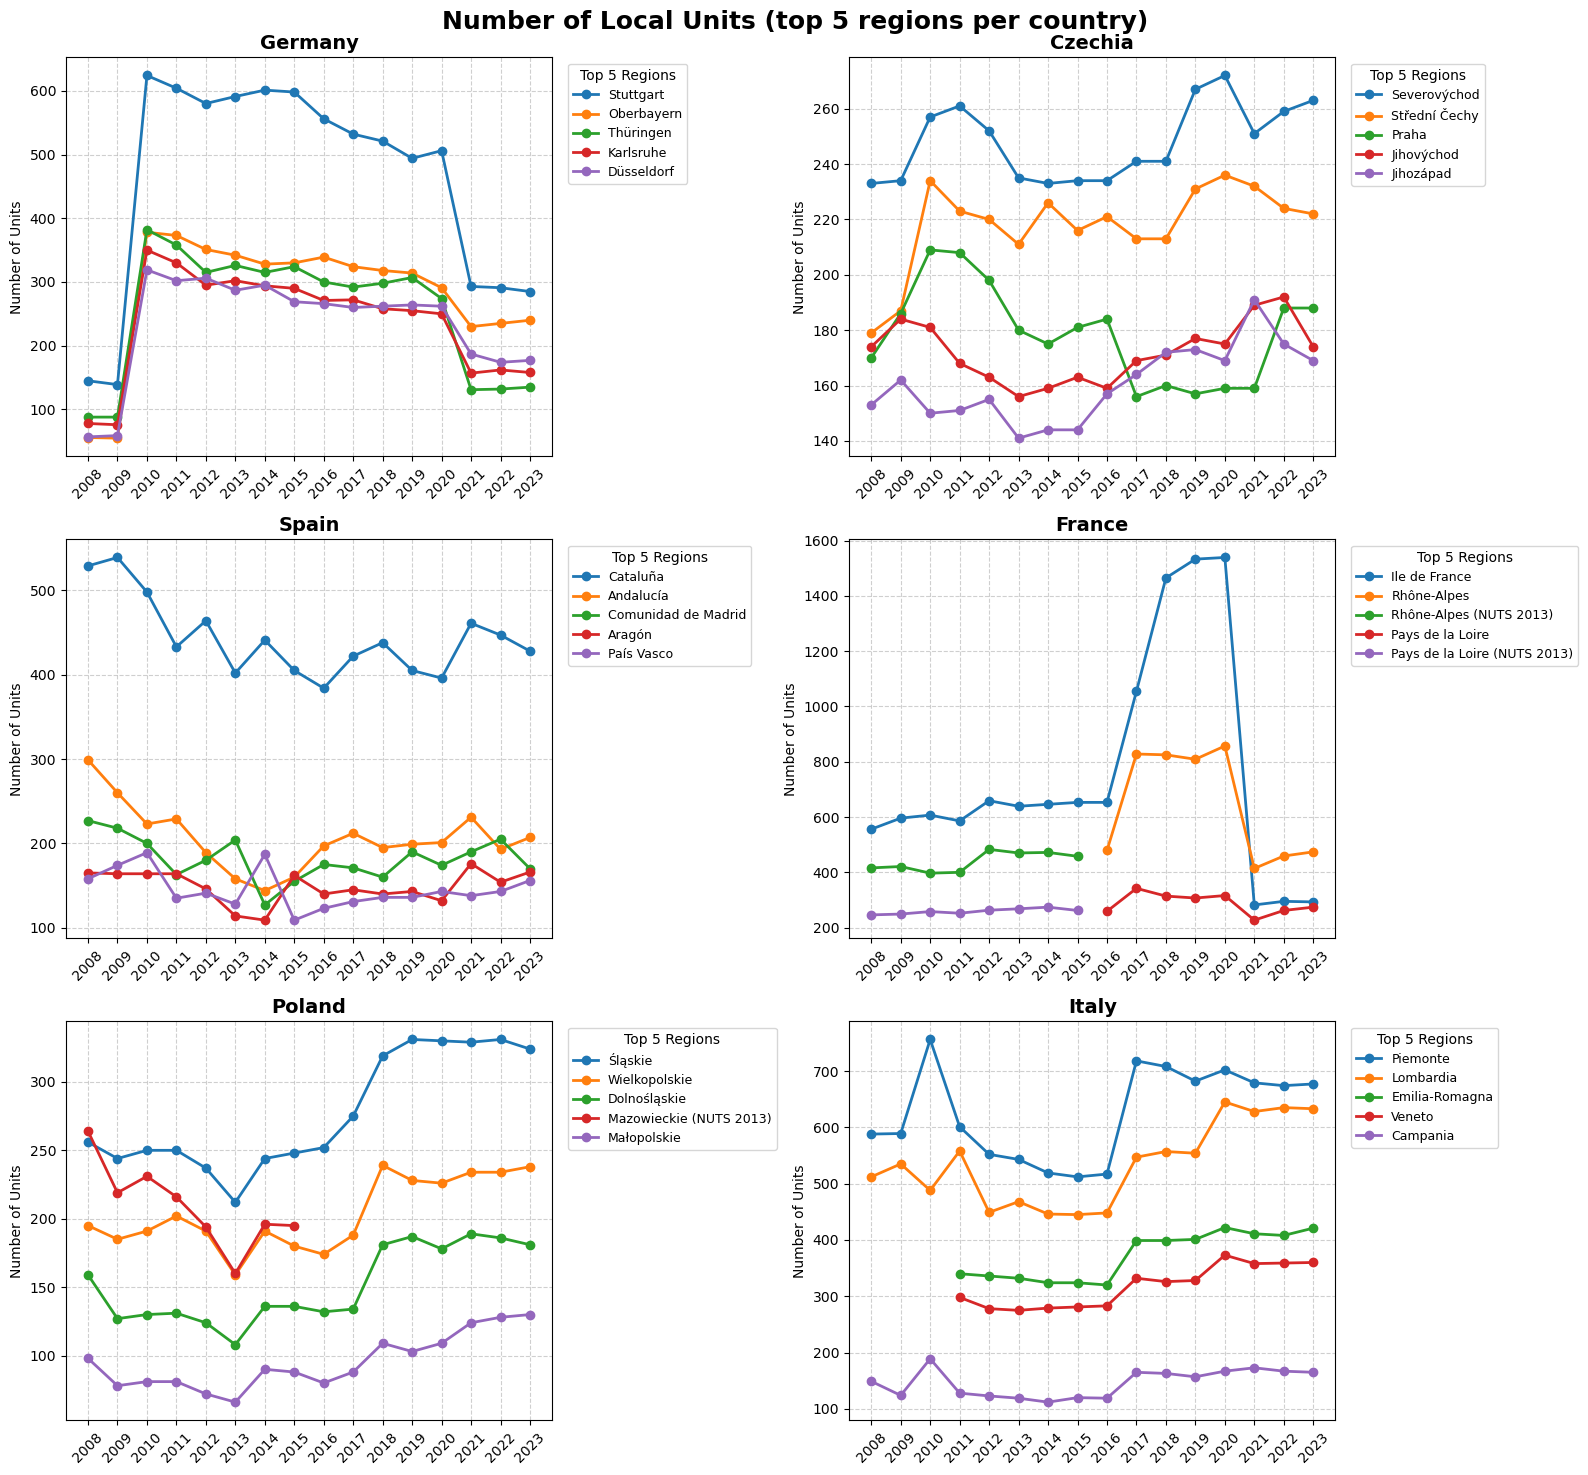

In [30]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the dataset
file_path = '../../03_data_raw/exploration_inputs/units_merged.xlsx'
df = pd.read_excel(file_path)

# Ensure GEO_Code is a string and drop any rows without a valid code
df = df.dropna(subset=['GEO_Code'])
df['GEO_Code'] = df['GEO_Code'].astype(str)

# Target countries and their standard NUTS codes
countries = {
    'DE': 'Germany',
    'CZ': 'Czechia',
    'ES': 'Spain',
    'FR': 'France',
    'PL': 'Poland',
    'IT': 'Italy'
}

# Isolate the columns containing the yearly numeric data
year_cols = [col for col in df.columns if col.isdigit()]

# Create a 3x2 grid of subplots (16 inches wide, 15 inches tall)
fig, axes = plt.subplots(3, 2, figsize=(16, 15))
fig.suptitle('Number of Local Units (top 5 regions per country)', fontsize=18, fontweight='bold')
axes = axes.flatten()

# Loop through each country to populate its respective subplot
for idx, (code, name) in enumerate(countries.items()):
    
    # Filter for the country's sub-regions. 
    # NUTS 2 regions generally have a 4-character code (e.g., DE11 for Stuttgart).
    # Using length == 4 prevents us from accidentally plotting the country-level total (e.g., 'DE')
    regions_df = df[df['GEO_Code'].str.startswith(code) & (df['GEO_Code'].str.len() == 4)].copy()
    
    # Sum the units across all available years to rank them, then grab the top 5
    regions_df['total_units'] = regions_df[year_cols].sum(axis=1)
    top_5_regions = regions_df.nlargest(5, 'total_units')
    
    ax = axes[idx]
    
    # Plot the trajectory for each of those top 5 regions
    for _, row in top_5_regions.iterrows():
        # Use GEO_Code as a fallback if the GEO_Label is missing
        label = row['GEO_Label']
        if pd.isna(label):
            label = row['GEO_Code']
        
        ax.plot(year_cols, row[year_cols].values, marker='o', linewidth=2, label=label)
        
    # Formatting for the specific subplot
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Units', fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Place the legend outside the plot area so it doesn't cover the lines
    ax.legend(title='Top 5 Regions', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

# Automatically adjust spacing between subplots to accommodate legends and titles
plt.tight_layout()

# Save the resulting figure
plt.savefig('top_regions_6_countries.png')
plt.show()

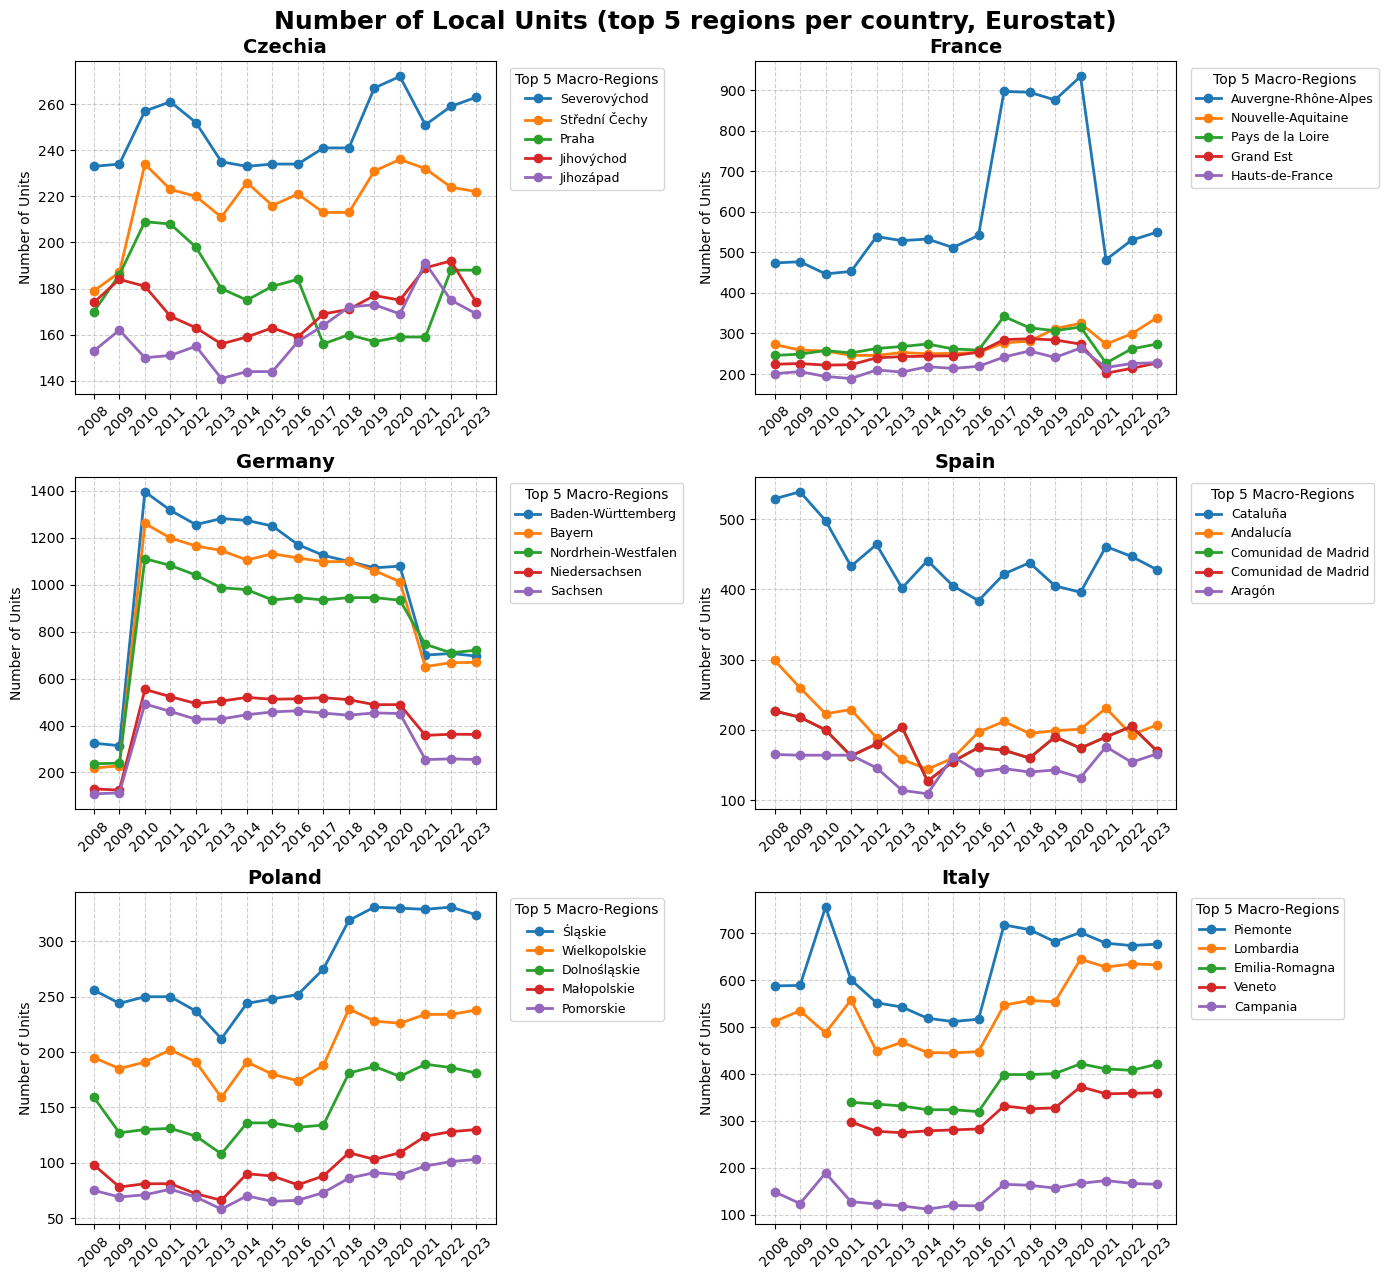

In [34]:
file_path = '../../03_data_raw/exploration_inputs/units_merged.xlsx'
df = pd.read_excel(file_path)

# Ensure GEO_Code is a string and filter valid rows
df = df.dropna(subset=['GEO_Code'])
df['GEO_Code'] = df['GEO_Code'].astype(str)

# 2. Define the Top 6 Countries to plot
countries = ['CZ', 'FR', 'DE', 'ES', 'PL', 'IT']
country_names = {
    'CZ': 'Czechia', 
    'FR': 'France', 
    'DE': 'Germany', 
    'ES': 'Spain', 
    'PL': 'Poland', 
    'IT': 'Italy'
}

# 3. Define valid macro-regions
valid_regions = {
    'DE': [
        "Baden-Württemberg", "Bayern", "Berlin", "Brandenburg", "Bremen", 
        "Hamburg", "Hessen", "Mecklenburg-Vorpommern", "Niedersachsen", 
        "Nordrhein-Westfalen", "Rheinland-Pfalz", "Saarland", "Sachsen", 
        "Sachsen-Anhalt", "Schleswig-Holstein", "Thüringen"
    ],
    'FR': [
        "Ile-de-France", "Centre — Val de Loire", "Bourgogne-Franche-Comté",
        "Normandie", "Hauts-de-France", "Grand Est", "Pays de la Loire",
        "Bretagne", "Nouvelle-Aquitaine", "Occitanie", "Auvergne-Rhône-Alpes",
        "Provence-Alpes-Côte d’Azur", "Corse"
    ],
    'CZ': ["Praha", "Střední Čechy", "Jihozápad", "Severozápad", "Severovýchod", "Jihovýchod", "Střední Morava", "Moravskoslezsko"],
    'PL': ["Małopolskie", "Śląskie", "Wielkopolskie", "Zachodniopomorskie", "Lubuskie", "Dolnośląskie", "Opolskie", "Kujawsko-Pomorskie", "Pomorskie", "Warmińsko-Mazurskie", "Podlaskie", "Warszawski stołeczny", "Mazowieckie regionalne", "Świętokrzyskie", "Lubelskie", "Podkarpackie", "Łódzkie"],
    'ES': ["Galicia", "Principado de Asturias", "Cantabria", "País Vasco", "Comunidad Foral de Navarra", "La Rioja", "Aragón", "Comunidad de Madrid", "Castilla y León", "Castilla-La Mancha", "Extremadura", "Cataluña", "Comunitat Valenciana", "Illes Balears", "Andalucía", "Región de Murcia", "Canarias"],
    'IT': ["Piemonte", "Valle d'Aosta/Vallée d'Aoste", "Liguria", "Lombardia", "Abruzzo", "Molise", "Campania", "Puglia", "Basilicata", "Calabria", "Sicilia", "Sardegna", "Provincia Autonoma di Bolzano/Bozen", "Provincia Autonoma di Trento", "Veneto", "Friuli-Venezia Giulia", "Emilia-Romagna", "Toscana", "Umbria", "Marche", "Lazio"]
}

# The columns containing yearly data
year_cols = [col for col in df.columns if col.isdigit()]

# Create a 3x2 grid of subplots
fig, axes = plt.subplots(3, 2, figsize=(14, 13))
fig.suptitle('Number of Local Units (top 5 regions per country, Eurostat)', fontsize=18, fontweight='bold')

axes = axes.flatten()

for idx, code in enumerate(countries):
    name = country_names[code]
    allowed_regions = valid_regions[code]
    
    # Filter the dataset using the explicit list of region names
    regions_df = df[df['GEO_Label'].isin(allowed_regions)].copy()
    
    # Sum the units across all years to rank them and get the top 5
    regions_df['total_units'] = regions_df[year_cols].sum(axis=1)
    top_5_regions = regions_df.nlargest(5, 'total_units')
    
    ax = axes[idx]
    
    # Plot the trajectory for each of the top 5 regions
    for _, row in top_5_regions.iterrows():
        label = row['GEO_Label']
        ax.plot(year_cols, row[year_cols].values, marker='o', linewidth=2, label=label)
        
    ax.set_title(name, fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Units', fontsize=10)
    ax.tick_params(axis='x', rotation=45)
    ax.grid(True, linestyle='--', alpha=0.6)
    
    # Add legend outside the specific subplot
    if not top_5_regions.empty:
        ax.legend(title='Top 5 Macro-Regions', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=9)

# Adjust layout 
plt.tight_layout()

# Save the figure
plt.savefig('top_macro_regions_6_countries.png')
plt.show()